# Online shopping habits

**Online Shopping Habits Survey**

Thank you for participating in this survey! Your responses will help us understand shopping preferences and improve online shopping experiences. This survey will take about 5 minutes.

---

### Section 1: General Information

1. What is your age group?

   * Under 18
   * 18–24
   * 25–34
   * 35–44
   * 45–54
   * 55+

2. What is your gender?

   * Male
   * Female
   * Non-binary / Prefer not to say

3. How often do you shop online?

   * Daily
   * Weekly
   * Monthly
   * A few times a year
   * Rarely

---

### Section 2: Shopping Preferences

4. What types of products do you usually buy online? (Select all that apply)

   * Clothing & Accessories
   * Electronics & Gadgets
   * Groceries
   * Beauty & Personal Care
   * Home & Furniture
   * Books & Media
   * Others (please specify)

5. Which device do you primarily use for online shopping?

   * Smartphone
   * Laptop
   * Desktop
   * Tablet

6. Which online platforms do you shop from most often? (Select all that apply)

   * Amazon
   * eBay
   * Walmart
   * Etsy
   * Brand websites
   * Other (please specify)



In [25]:
import random
import numpy as np
import pandas as pd
from datetime import datetime

random.seed(42)
np.random.seed(42)

n = 10000

age_groups = ["Under 18", "18–24", "25–34", "35–44", "45–54", "55+"]
age_probs = [0.05, 0.22, 0.30, 0.20, 0.13, 0.10]

genders = ["Male", "Female", "Non-binary / Prefer not to say"]
gender_probs = [0.48, 0.48, 0.04]

frequency = ["Daily", "Weekly", "Monthly", "A few times a year", "Rarely"]
freq_probs = [0.05, 0.35, 0.30, 0.20, 0.10]

products = ["Clothing & Accessories", "Electronics & Gadgets", "Groceries", 
            "Beauty & Personal Care", "Home & Furniture", "Books & Media", "Others"]
# base probabilities for single pick, we'll allow multi-select
prod_base = [0.30, 0.25, 0.18, 0.15, 0.10, 0.20, 0.05]

devices = ["Smartphone", "Laptop", "Desktop", "Tablet"]
device_probs = [0.65, 0.25, 0.05, 0.05]

platforms = ["Amazon", "eBay", "Walmart", "Etsy", "Brand websites", "Other"]
plat_base = [0.6, 0.15, 0.10, 0.07, 0.25, 0.03]  # overlaps allowed

factors = ["Price & Discounts", "Product Variety", "Convenience", "Delivery Speed", "Reviews & Ratings", "Return/Refund Policies"]
factor_probs = [0.7, 0.45, 0.8, 0.6, 0.65, 0.5]

satisfaction = ["Very satisfied", "Satisfied", "Neutral", "Dissatisfied", "Very dissatisfied"]
sat_probs = [0.20, 0.45, 0.20, 0.10, 0.05]

abandoned = ["Yes", "No", "Not sure"]
aband_probs = [0.55, 0.40, 0.05]
aband_reasons = ["High shipping costs", "Complicated checkout process", "Found a better deal elsewhere", "Changed my mind", "Payment issues"]

confidence = ["Very confident", "Somewhat confident", "Neutral", "Not very confident", "Not confident at all"]
conf_probs = [0.25, 0.40, 0.20, 0.10, 0.05]

reviews_influence = ["Yes, always", "Sometimes", "Rarely", "Never"]
rev_probs = [0.35, 0.45, 0.15, 0.05]

future_interest = ["Subscription services", "AI-based product recommendations", "Virtual try-on (AR/VR)", "Drone delivery"]
future_probs = [0.35, 0.7, 0.45, 0.15]

open_ended_samples = [
    "Faster delivery and cheaper shipping.",
    "Better product descriptions and more accurate images.",
    "Easier returns and clearer refund policies.",
    "More trustworthy reviews and less fake feedback.",
    "Bundled discounts and loyalty rewards.",
    "Improved mobile checkout experience.",
    "More local/eco-friendly shipping options.",
    "AR try-on for clothing and furniture.",
    "Better customer support availability."
]

def multi_select(options, base_probs, min_sel=1, max_sel=None):
    if max_sel is None:
        max_sel = min(len(options), 4)
    k = np.random.choice(range(min_sel, max_sel+1), p=None)
    # sample without replacement weighted by base_probs
    chosen = list(np.random.choice(options, size=k, replace=False, p=np.array(base_probs)/np.sum(base_probs)))
    return "; ".join(chosen)

data = []
for i in range(n):
    age = np.random.choice(age_groups, p=age_probs)
    gender = np.random.choice(genders, p=gender_probs)
    freq = np.random.choice(frequency, p=freq_probs)
    
    prods = multi_select(products, prod_base, min_sel=1, max_sel=3)
    device = np.random.choice(devices, p=device_probs)
    plats = multi_select(platforms, plat_base, min_sel=1, max_sel=3)
    
    fac = multi_select(factors, factor_probs, min_sel=1, max_sel=4)
    sat = np.random.choice(satisfaction, p=sat_probs)
    aband = np.random.choice(abandoned, p=aband_probs)
    aband_reason = ""
    if aband == "Yes":
        aband_reason = random.choice(aband_reasons)
    conf = np.random.choice(confidence, p=conf_probs)
    rev = np.random.choice(reviews_influence, p=rev_probs)
    future = multi_select(future_interest, future_probs, min_sel=0, max_sel=3)  # allow 0 selection
    # If empty, store as blank
    if future.strip() == "":
        future = "None"
    open_resp = random.choice(open_ended_samples)
    
    data.append({
        "RespondentID": f"R{i+1:04d}",
        "Age group": age,
        "Gender": gender,
        "How often shop online": freq,
        "Products bought (multi-select)": prods,
        "Primary device": device,
        "Platforms (multi-select)": plats,
        "Decision factors (multi-select)": fac,
        "Overall satisfaction": sat,
        "Abandoned cart": aband,
        "Abandon reason": aband_reason,
        "Payment confidence": conf,
        "Reviews influence": rev,
        "Interest in future features (multi-select)": future,
        
        "Timestamp": datetime.utcnow().isoformat() + "Z"
    })

df = pd.DataFrame(data)

# Occasionally add a few realistic anomalies (e.g., missing values)
for _ in range(5):
    idx = np.random.randint(0, n)
    col = np.random.choice(df.columns)
    df.at[idx, col] = np.nan


In [26]:
population = df.copy()
len(population)

10000

# Choose and Apply a Sampling Technique:
Select ONE of these sampling methods:
    - Simple random sampling

Document your sampling plan and justify your choice:
    Simple random sampling (e.g., randomly selecting names from a complete roster), because:
    - Easy to understand
    - Requires minimal knowledge of the population
    - Free from researcher bias
    - Highly representative if done properly

Implement your plan to collect data from at least ~ 5 participants, the more the better:

In [27]:
# Set a sample size
sample_size = 100  # adjust as needed

# Draw a random sample
sample = population.sample(n=sample_size, random_state=42)
len(sample)

100

In [28]:
sample.head()

,RespondentID,Age group,Gender,How often shop online,Products bought (multi-select),Primary device,Platforms (multi-select),Decision factors (multi-select),Overall satisfaction,Abandoned cart,Abandon reason,Payment confidence,Reviews influence,Interest in future features (multi-select),Timestamp
6252,R6253,25–34,Male,A few times a year,Clothing & Accessories; Books & Media; Electro...,Tablet,eBay; Brand websites,Price & Discounts; Convenience; Delivery Speed...,Neutral,Yes,Changed my mind,Very confident,Sometimes,None,2025-10-02T09:05:59.619211Z
4684,R4685,25–34,Female,Weekly,Others; Groceries,Smartphone,Brand websites,Delivery Speed,Very satisfied,Yes,Payment issues,Somewhat confident,Rarely,AI-based product recommendations; Virtual try-...,2025-10-02T09:05:59.091655Z
1731,R1732,25–34,Male,A few times a year,Clothing & Accessories; Electronics & Gadgets;...,Smartphone,Brand websites; eBay,Reviews & Ratings; Price & Discounts,Very satisfied,Yes,High shipping costs,Neutral,Never,None,2025-10-02T09:05:58.073538Z
4742,R4743,35–44,Male,Weekly,Groceries; Electronics & Gadgets,Smartphone,Amazon,Delivery Speed,Satisfied,Yes,Complicated checkout process,Somewhat confident,Sometimes,None,2025-10-02T09:05:59.111891Z
4521,R4522,18–24,Male,Weekly,Groceries; Electronics & Gadgets; Home & Furni...,Laptop,eBay; Amazon,Return/Refund Policies; Price & Discounts; Rev...,Very satisfied,Not sure,,Very confident,Rarely,Virtual try-on (AR/VR); AI-based product recom...,2025-10-02T09:05:59.036609Z


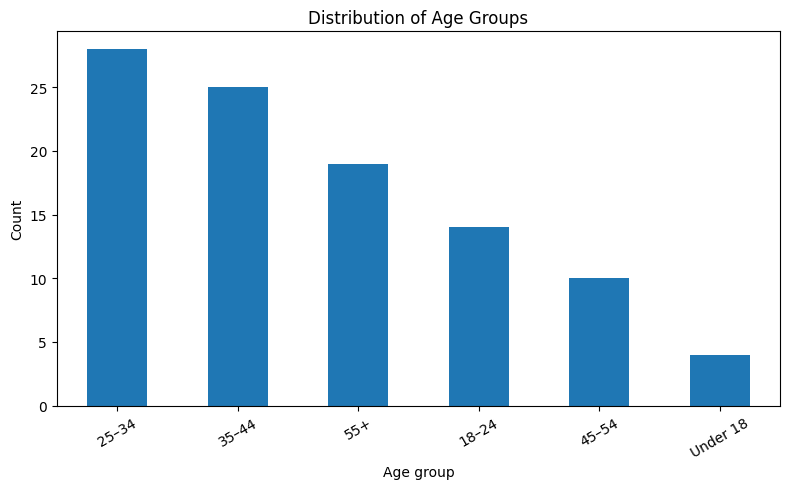

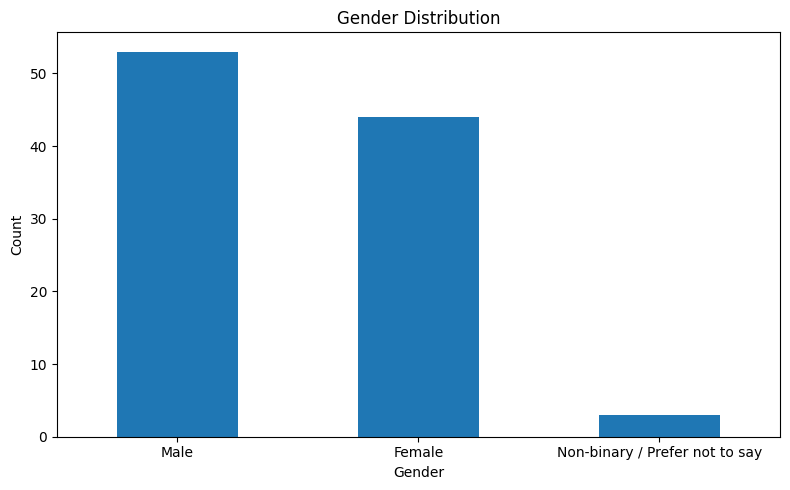

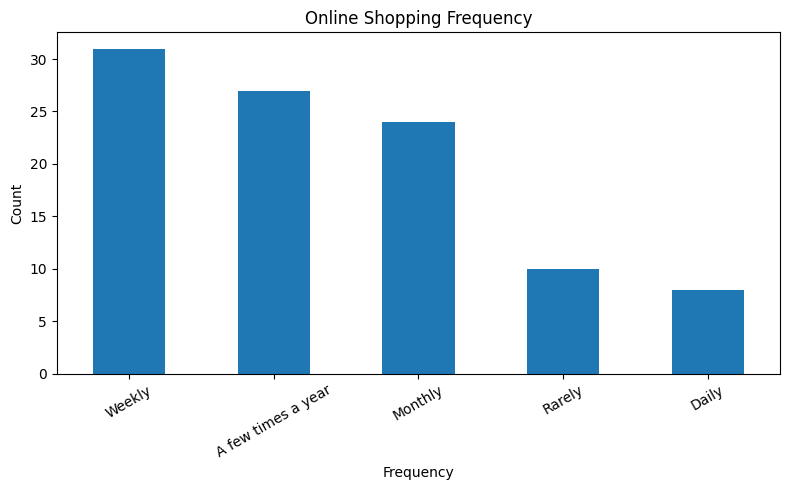

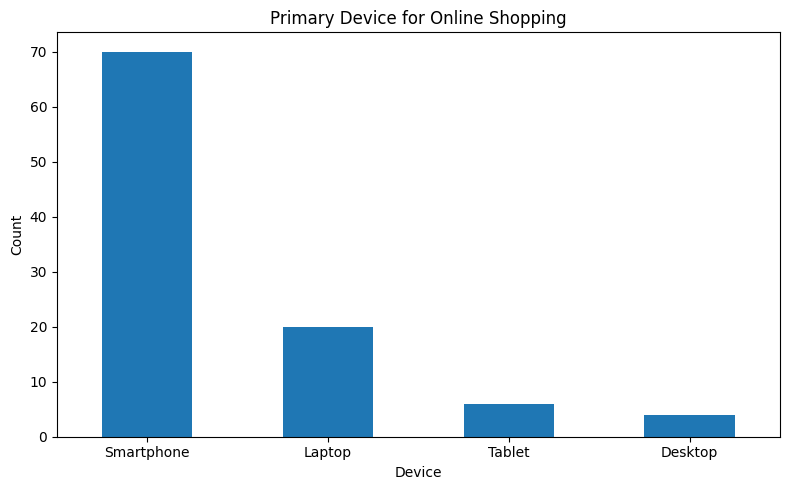

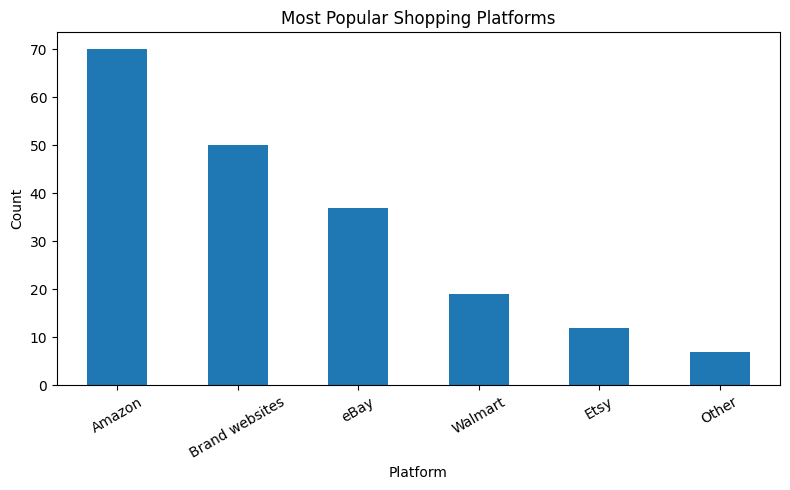

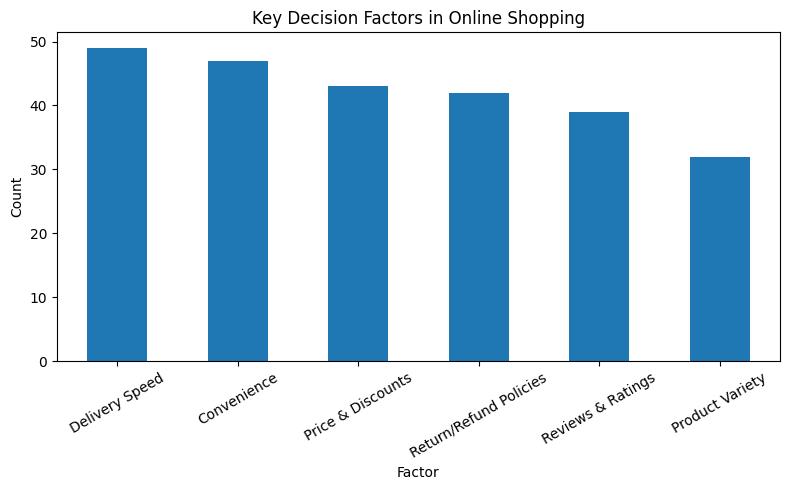

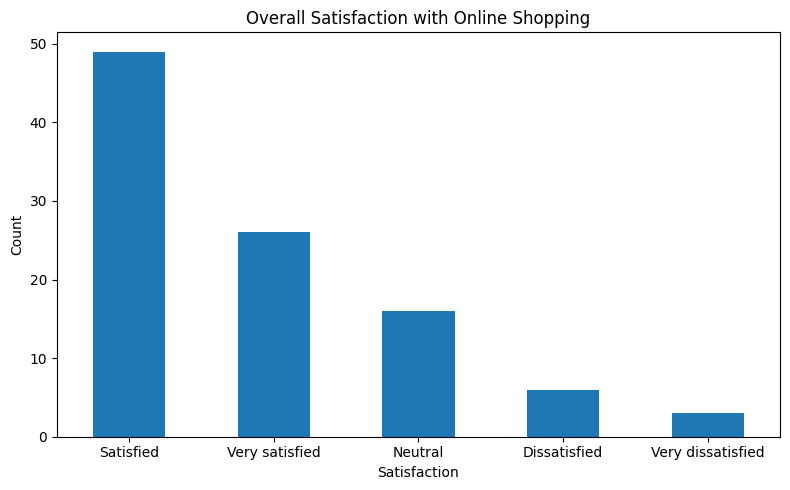

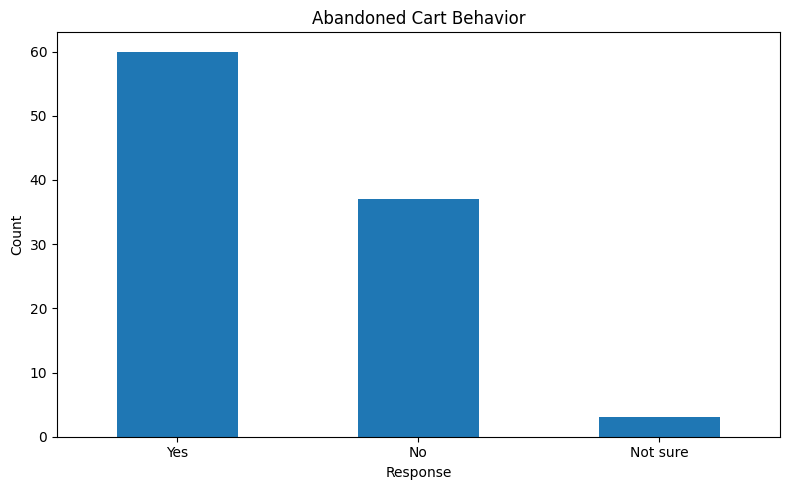

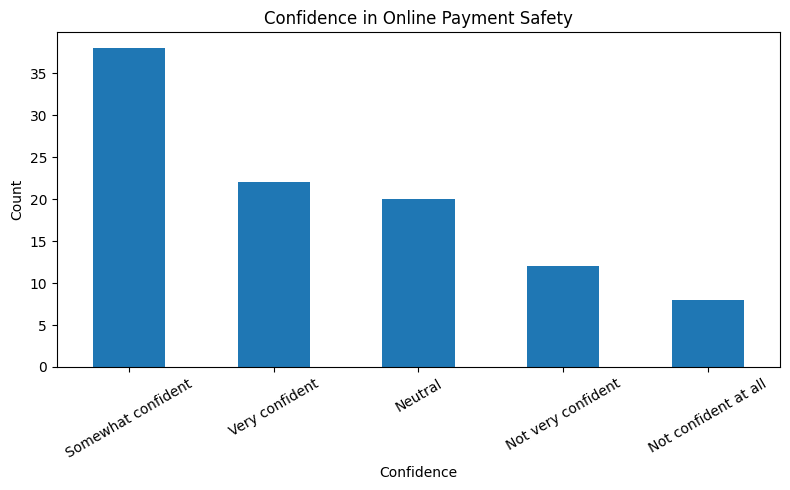

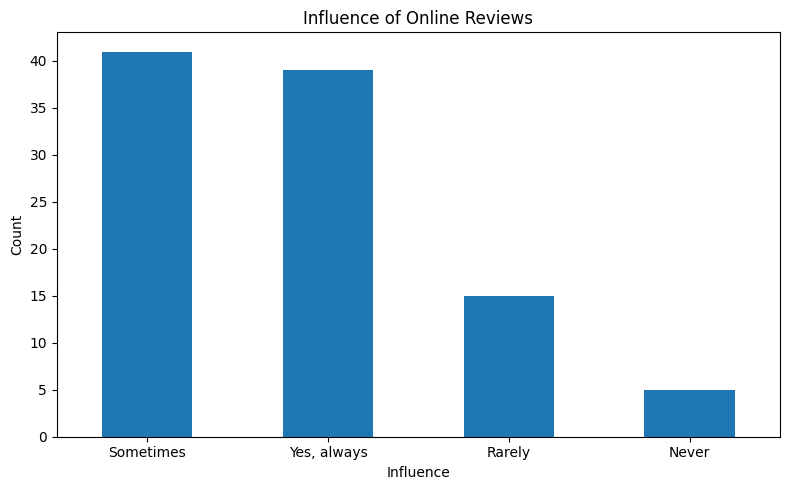

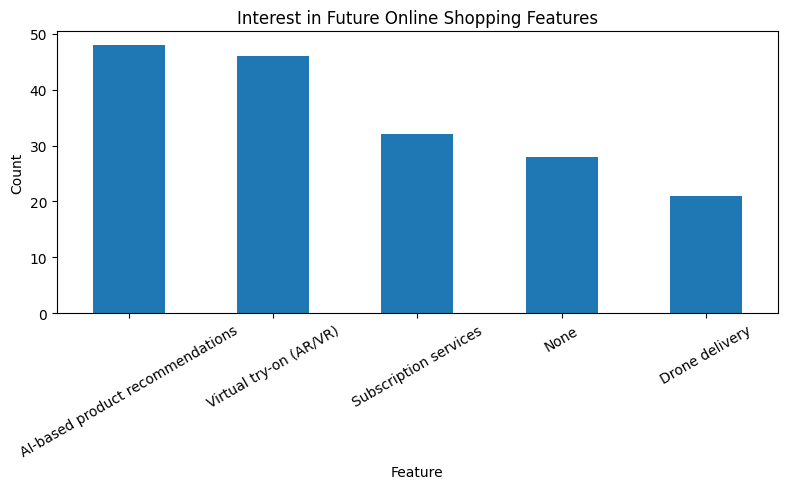

In [29]:
import matplotlib.pyplot as plt

# Helper function for bar charts
def plot_bar(data, title, xlabel, ylabel="Count", rotation=0):
    plt.figure(figsize=(8,5))
    data.value_counts().plot(kind="bar")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()

# 1. Age group distribution
plot_bar(sample["Age group"].dropna(), "Distribution of Age Groups", "Age group", rotation=30)

# 2. Gender distribution
plot_bar(sample["Gender"].dropna(), "Gender Distribution", "Gender")

# 3. Shopping frequency
plot_bar(sample["How often shop online"].dropna(), "Online Shopping Frequency", "Frequency", rotation=30)

# 4. Primary device used
plot_bar(sample["Primary device"].dropna(), "Primary Device for Online Shopping", "Device")

# 5. Platforms (multi-select) - split into counts
platform_counts = sample["Platforms (multi-select)"].dropna().str.split("; ").explode().value_counts()
plt.figure(figsize=(8,5))
platform_counts.plot(kind="bar")
plt.title("Most Popular Shopping Platforms")
plt.xlabel("Platform")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 6. Decision factors (multi-select)
factor_counts = sample["Decision factors (multi-select)"].dropna().str.split("; ").explode().value_counts()
plt.figure(figsize=(8,5))
factor_counts.plot(kind="bar")
plt.title("Key Decision Factors in Online Shopping")
plt.xlabel("Factor")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 7. Overall satisfaction
plot_bar(sample["Overall satisfaction"].dropna(), "Overall Satisfaction with Online Shopping", "Satisfaction")

# 8. Abandoned cart
plot_bar(sample["Abandoned cart"].dropna(), "Abandoned Cart Behavior", "Response")

# 9. Payment confidence
plot_bar(sample["Payment confidence"].dropna(), "Confidence in Online Payment Safety", "Confidence", rotation=30)

# 10. Reviews influence
plot_bar(sample["Reviews influence"].dropna(), "Influence of Online Reviews", "Influence")

# 11. Future features interest (multi-select)
future_counts = sample["Interest in future features (multi-select)"].dropna().str.split("; ").explode().value_counts()
plt.figure(figsize=(8,5))
future_counts.plot(kind="bar")
plt.title("Interest in Future Online Shopping Features")
plt.xlabel("Feature")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Consider what your findings suggest about the population as a whole:
According to the data:

	- young people shop online more often than old people
	- most people shop weekly online and use the smartphone to do so
	- most popular platform is amazon

# Evaluate Sampling Error:
2. Potential Sources of Sampling Error in Your Study

Sample Size
- Small samples (e.g., 10 respondents) may not reflect the distribution of age groups, genders, or shopping behavior.
- Effect: Estimates like average satisfaction or proportion of abandoned carts may vary widely.

Random Variation
- Randomly drawing respondents can lead to unintentional bias; e.g., by chance, more females than males may appear in the sample.
- Effect: Certain trends may appear stronger or weaker than they actually are.
- Solution: Repeat sampling multiple times and average results (Monte Carlo approach).

Multi-Select Columns
- Columns like “Products bought” or “Decision factors” have multiple responses; a small sample might miss some categories.
- Effect: Some popular items or factors may appear underrepresented.


# Application:
Businesses can leverage survey data on customer behavior and preferences to make strategic decisions, such as:

a. Marketing Strategy
- Determine which platforms customers prefer for shopping (e.g., Amazon, brand websites).
- Identify the most influential decision factors (price, reviews, delivery speed) to tailor promotions and advertising campaigns.

b. Product Development & Feature Prioritization
- Understand interest in future features (e.g., AR/VR virtual try-on) to guide product enhancements.
- Discover which product categories are most popular to adjust inventory or expand offerings.

c. Customer Experience Optimization
- Track abandoned cart reasons (e.g., high shipping costs) to reduce friction in the purchase process.
- Monitor payment confidence to improve checkout security or introduce preferred payment methods.v